# Week 1: MLB breakout hitter exploration

Feature season t, outcome season t+1; at least 300 PA in both seasons. This creates a retrospective qualifying population. All rates are fractions. No model training is performed. Correlation does not imply causation or predictive importance.

FanGraphs wRC+ retains its unrounded API precision. Both 2020 transitions have zero qualifying rows under the unchanged 300-PA rule; their breakout rates are undefined.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.explore_data import explore, main
from src.validate_data import FEATURE_COLUMNS
path = ROOT / 'data/processed/mlb_breakout_dataset.csv'
if path.exists():
    df = pd.read_csv(path)
    analyses = explore(df)
    display(pd.Series({'observations': len(df), 'unique_hitters': df.player_id.nunique(),
                      'breakouts': df.breakout.sum(), 'non_breakouts': (df.breakout == 0).sum(),
                      'breakout_percent': df.breakout.mean()*100}))
else:
    analyses = {}
    main()
    print('Collection incomplete. See results/metrics/week1_summary.md. No results are fabricated.')

observations        1206.000000
unique_hitters       495.000000
breakouts            188.000000
non_breakouts       1018.000000
breakout_percent      15.588723
dtype: float64

## Observations and breakout rate by starting season

In [2]:
if analyses:
    display(analyses['season'])

,observations,breakouts,breakout_percent
season,,,
2017,219,39,17.808219
2018,187,29,15.508021
2019,0,0,NaN
2020,0,0,NaN
2021,192,35,18.229167
2022,202,25,12.376238
2023,207,36,17.391304
2024,199,24,12.060302


## Missing values by predictor

In [3]:
if analyses:
    display(analyses['missing'])

,missing,missing_percent
age,0,0.0
pa,0,0.0
wrc_plus,0,0.0
woba,0,0.0
iso,0,0.0
babip,0,0.0
bb_rate,0,0.0
k_rate,0,0.0
chase_rate,0,0.0
contact_rate,0,0.0


## Age groups: counts and breakout rates

In [4]:
if analyses:
    display(analyses['age'])

,observations,breakout_percent
age,,
24 and younger,204,23.529412
25–29,620,15.161290
30 and older,382,12.041885


## Statcast coverage

In [5]:
if analyses:
    display(analyses['coverage'])

,avg_exit_velocity,hard_hit_rate,barrel_rate,avg_launch_angle,xba,xwoba
season,,,,,,
2017,100.0,100.0,100.0,100.0,100.0,100.0
2018,100.0,100.0,100.0,100.0,100.0,100.0
2019,NaN,NaN,NaN,NaN,NaN,NaN
2020,NaN,NaN,NaN,NaN,NaN,NaN
2021,100.0,100.0,100.0,100.0,100.0,100.0
2022,100.0,100.0,100.0,100.0,100.0,100.0
2023,100.0,100.0,100.0,100.0,100.0,100.0
2024,100.0,100.0,100.0,100.0,100.0,100.0


## Traditional and Statcast distributions: summary statistics

In [6]:
if analyses:
    display(analyses['group_summary'])

wrc_plus                                      age                    \
            count        mean      median        std count       mean median   
breakout                                                                       
0            1018  111.636815  109.579168  22.790001  1018  28.041257   28.0   
1             188   94.149094   92.644250  21.269140   188  27.218085   27.0   

                   k_rate            ... hard_hit_rate           barrel_rate  \
               std  count      mean  ...        median       std       count   
breakout                             ...                                       
0         3.482823   1018  0.208592  ...        0.3995  0.077174        1018   
1         3.479550    188  0.218891  ...        0.3855  0.074355         188   

                                     xwoba                             
              mean  median       std count      mean median       std  
breakout                                                               
0         0.083496  0.0790  0.041883  1018  0.331885  0.330  0.034157  
1         0.077622  0.0705  0.038699   188  0.317686  0.314  0.032812  

[2 rows x 32 columns]

## Exploratory associations with future wRC+ change

In [7]:
if analyses:
    display(analyses['relationships'])

,Pearson correlation with change
wrc_plus,-0.453797
woba,-0.445550
babip,-0.322349
iso,-0.278795
xwoba,-0.264140
xba,-0.220146
barrel_rate,-0.154202
age,-0.105815
bb_rate,-0.105364
hard_hit_rate,-0.103718


## 15 largest actual qualifying improvements

In [8]:
if analyses:
    display(analyses['top'])

,player_name,season,wrc_plus,next_season_wrc_plus,wrc_plus_change,pa,next_season_pa
187,Mookie Betts,2017,106.636390,184.996974,78.360584,712.0,614.0
1018,George Springer,2024,94.324584,166.003217,71.678633,614.0,586.0
1119,Bo Bichette,2024,69.924802,133.616416,63.691613,336.0,628.0
842,Jurickson Profar,2023,77.520546,139.249978,61.729432,521.0,668.0
859,Carlos Correa,2023,94.074027,154.617688,60.543661,580.0,367.0
472,Aaron Judge,2021,149.982602,206.154837,56.172234,633.0,696.0
731,Ronald Acuña Jr.,2022,115.387222,171.448727,56.061506,533.0,735.0
678,Corey Seager,2022,116.573343,172.521755,55.948412,663.0,536.0
1002,Brenton Doyle,2023,44.282328,97.774858,53.492530,431.0,603.0
985,Bobby Witt Jr.,2023,115.848973,169.094550,53.245577,694.0,709.0


## Figures
Missing observations are omitted from relevant plots, with no imputation. The +20 line marks the breakout threshold.

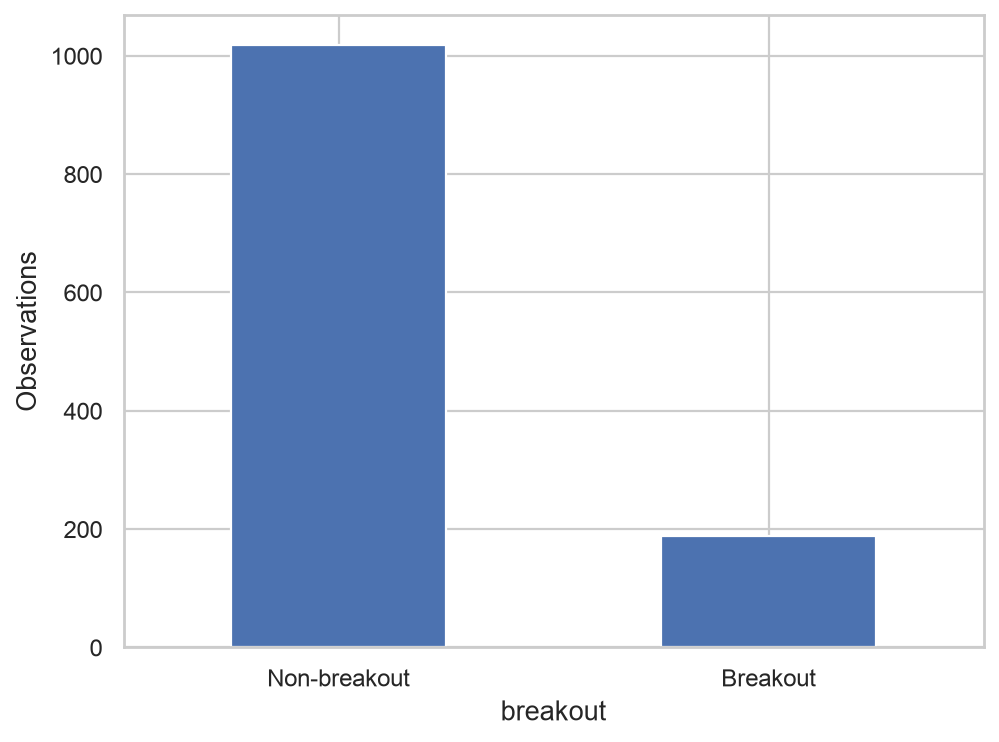

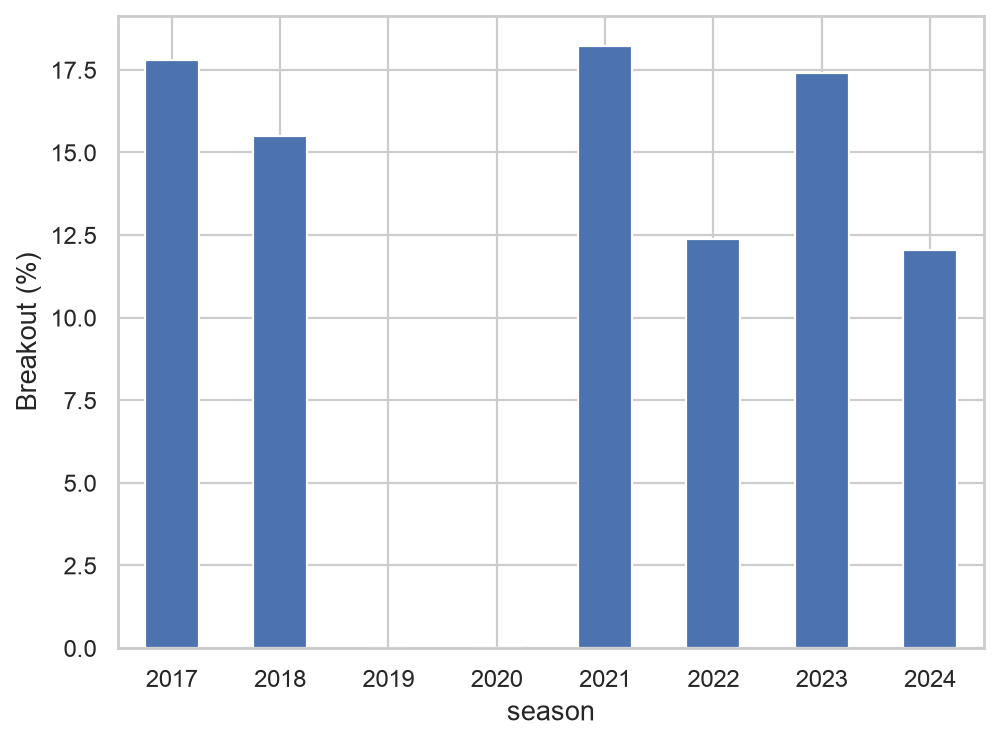

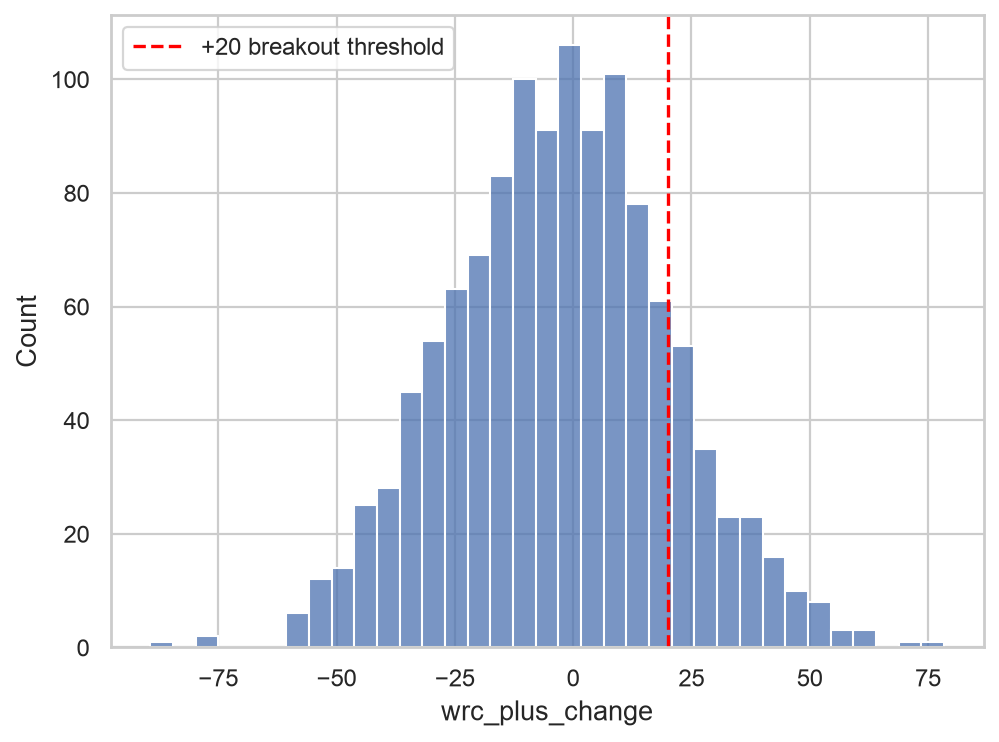

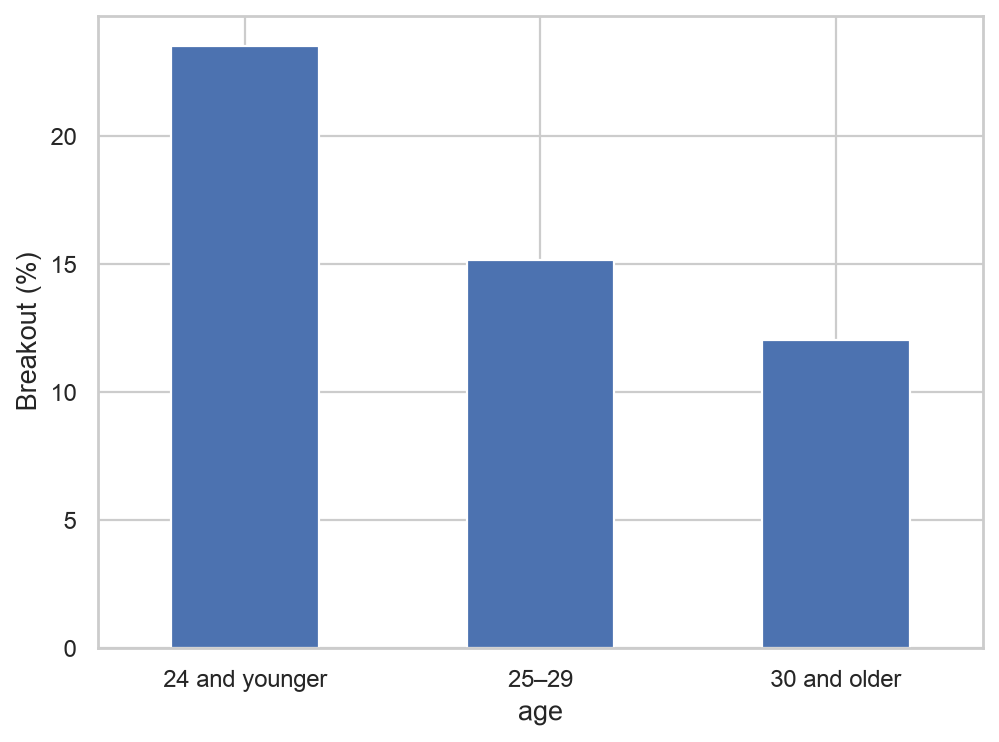

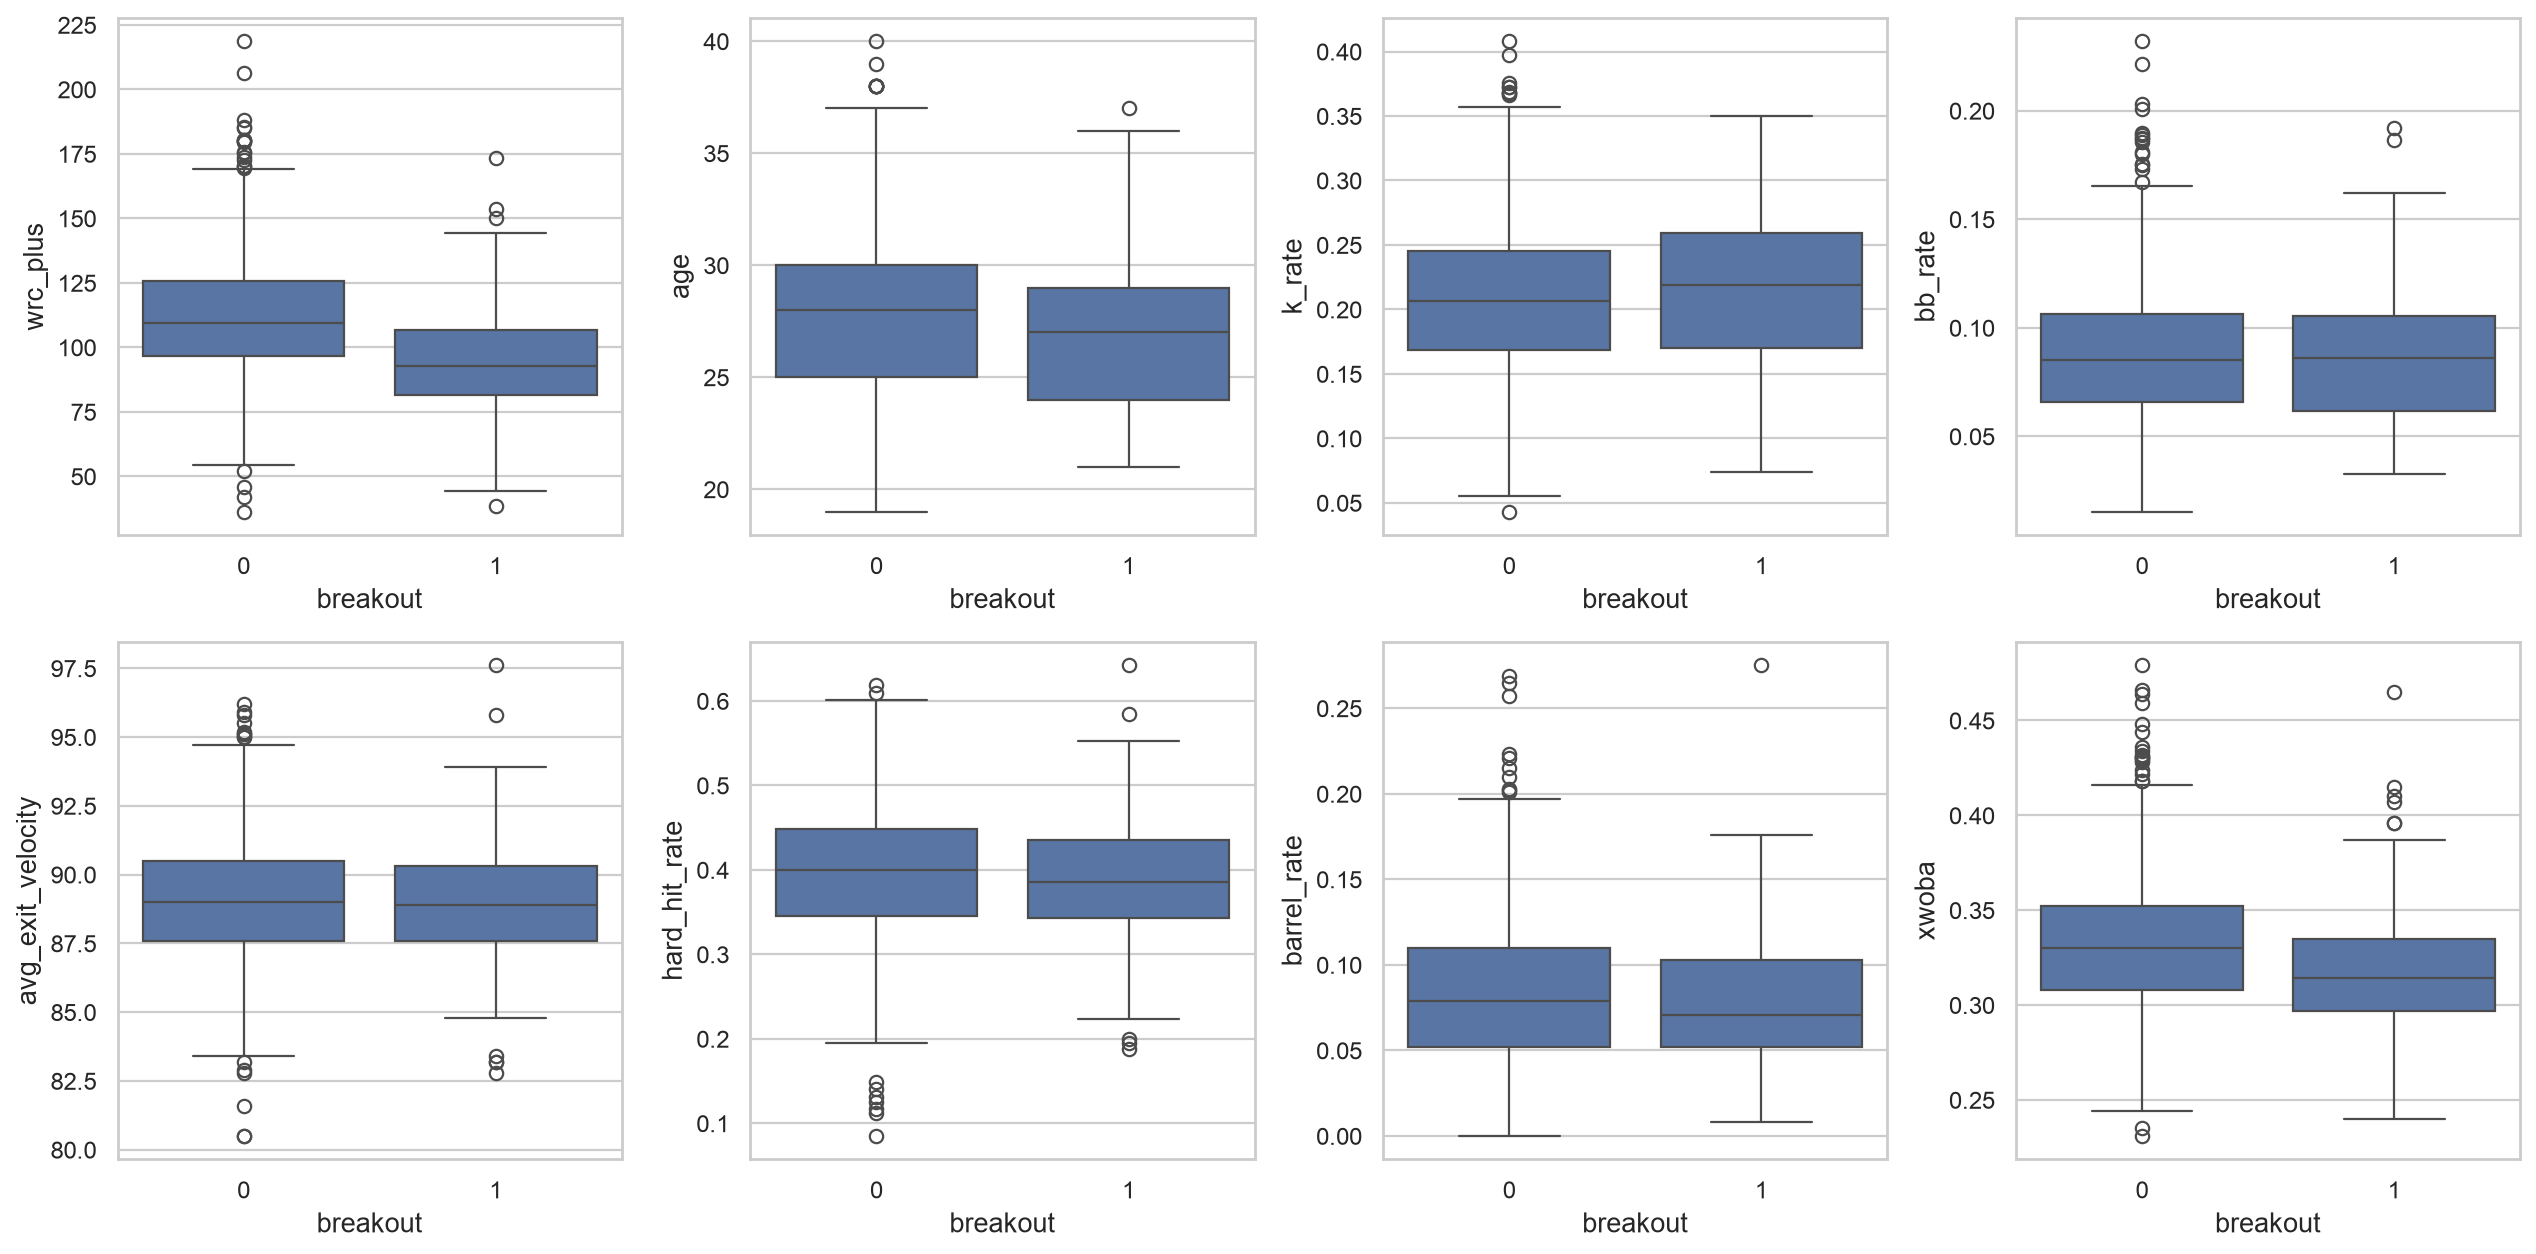

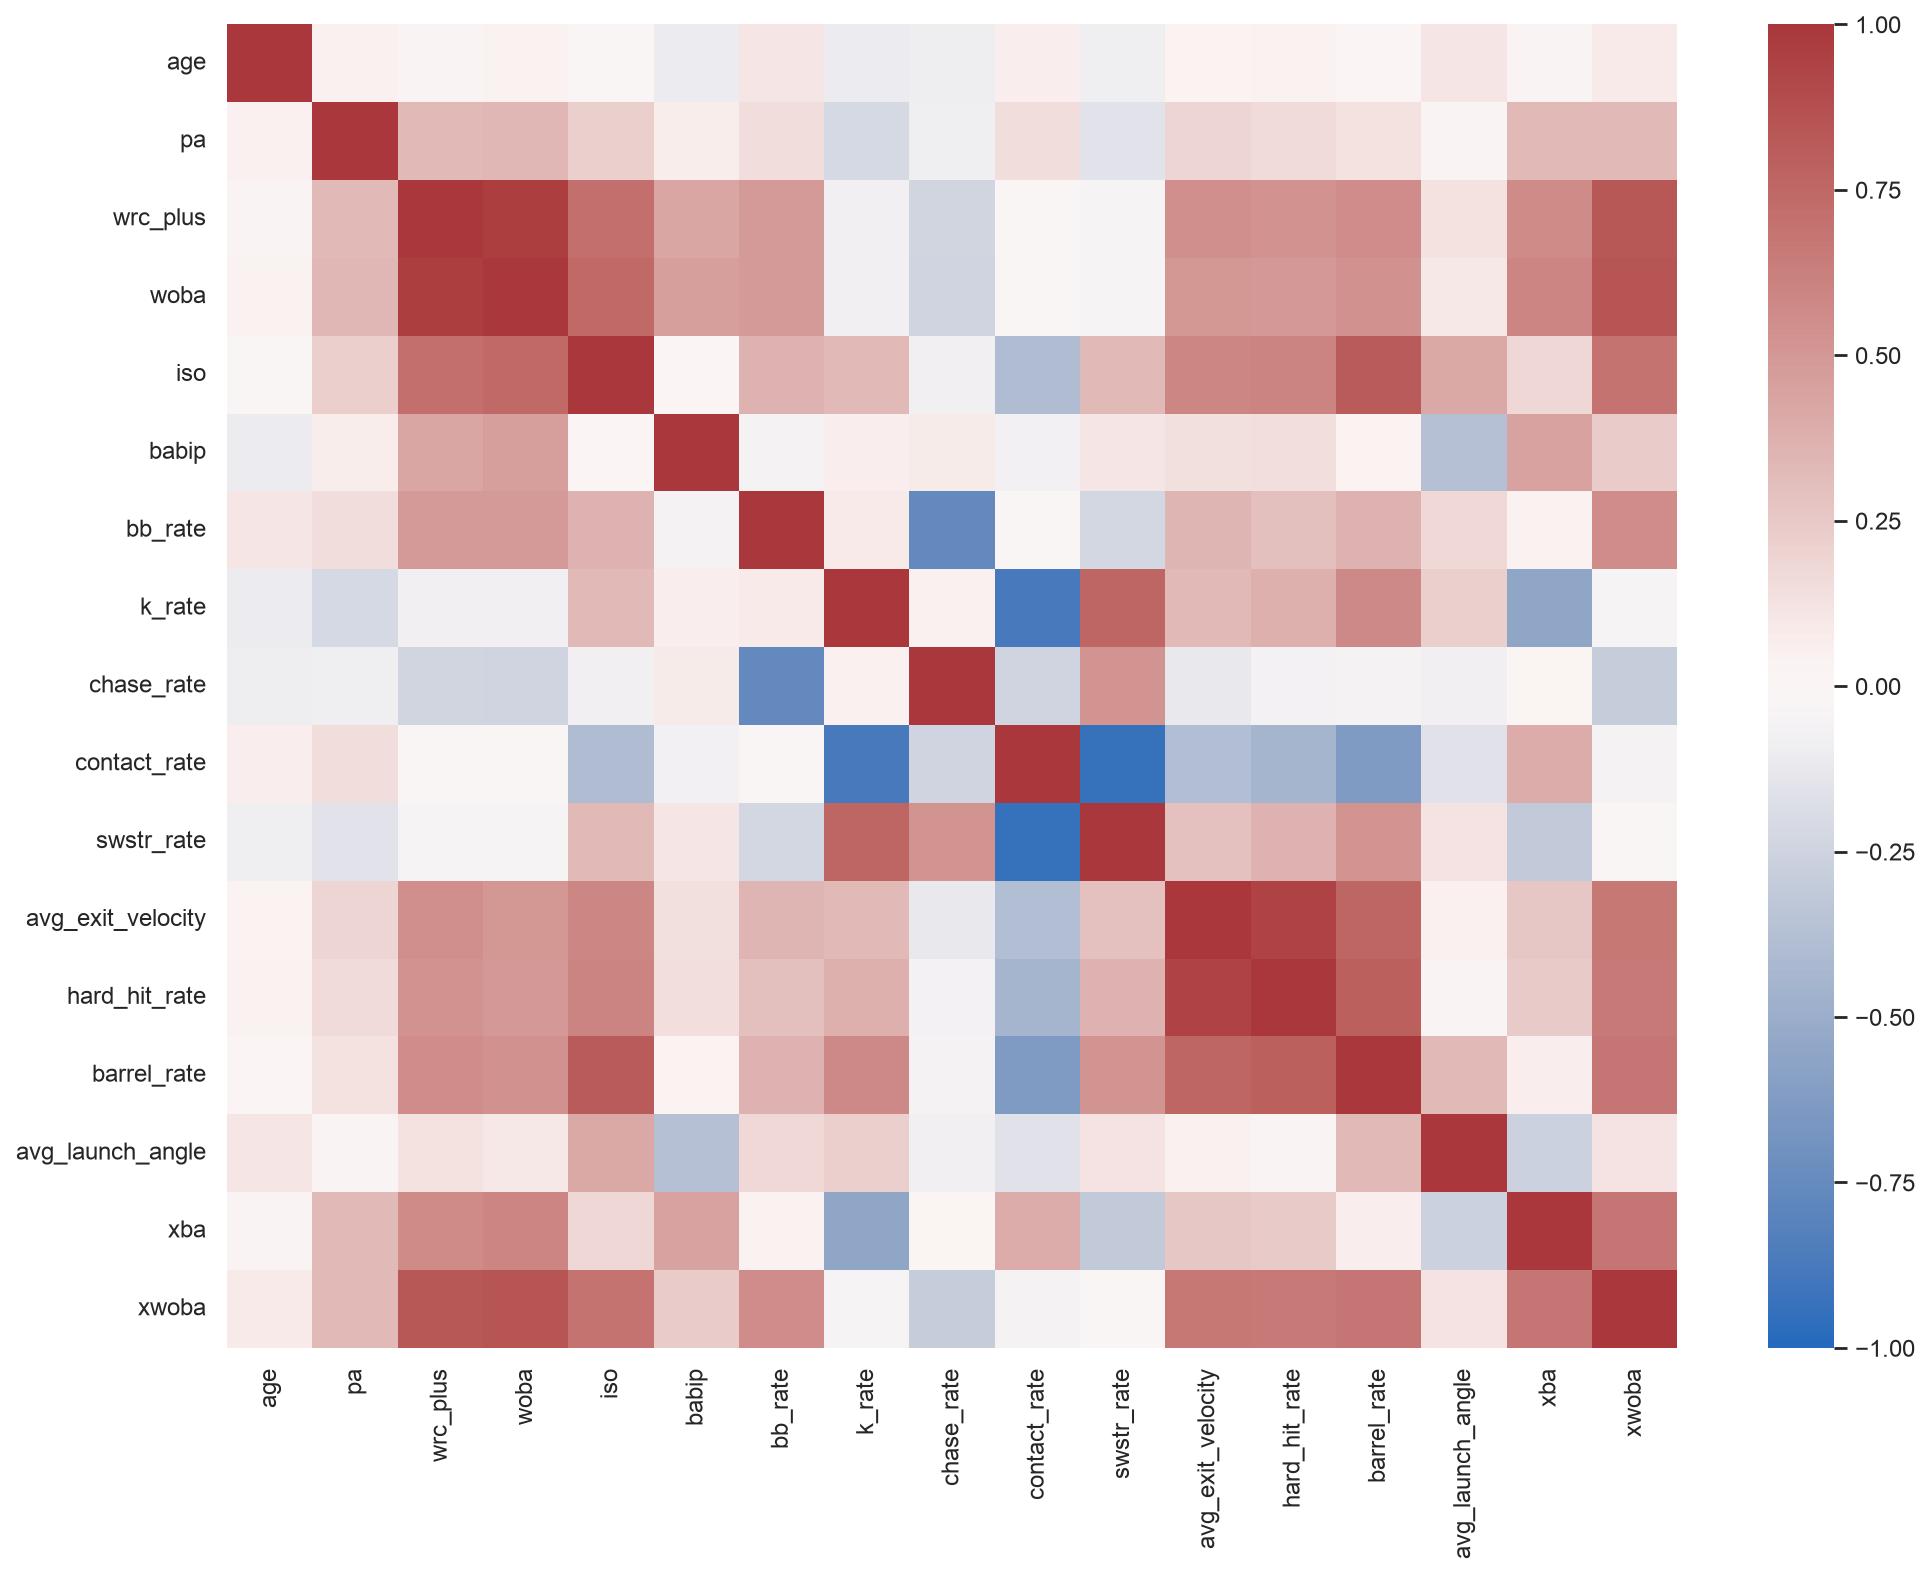

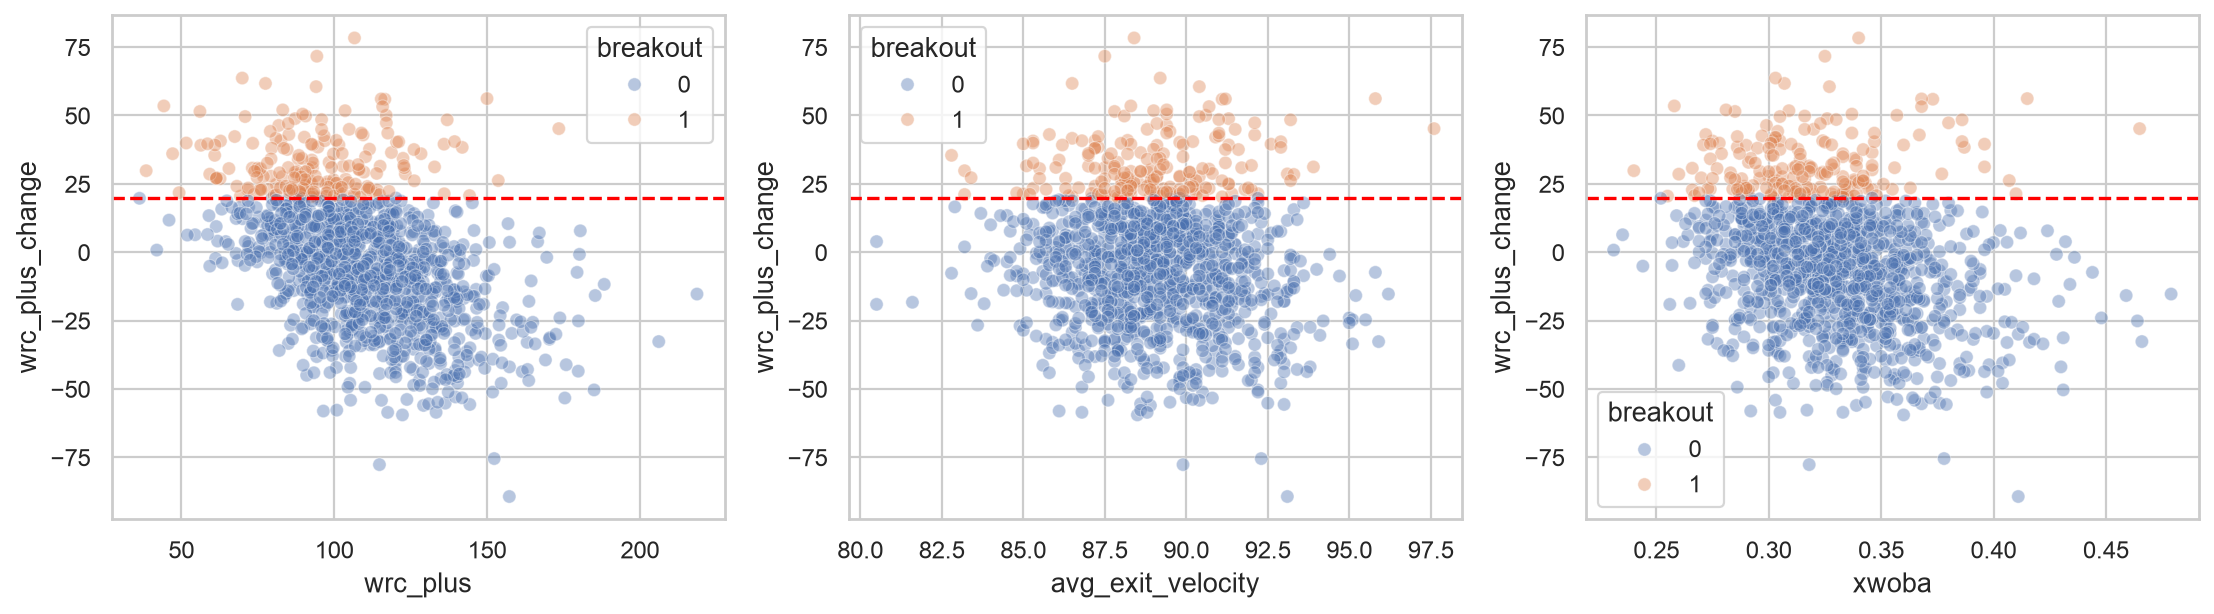

In [9]:
if analyses:
    for name in ['class_balance', 'breakout_by_season', 'wrc_plus_change', 'breakout_by_age', 'feature_distributions', 'predictor_correlations', 'feature_change_relationships']:
        display(Image(filename=str(ROOT / 'results/figures' / f'{name}.png')))

## Merge quality and qualification by transition
Stable FanGraphs and MLBAM IDs were independently checked against Chadwick. No names are used as join keys.

In [10]:
if analyses:
    display(pd.read_csv(ROOT / 'results/metrics/qualification_by_transition.csv'))
    import json
    audit = json.loads((ROOT / 'results/metrics/collection_report.json').read_text())
    display(pd.DataFrame({year: {key: record.get(key) for key in ['matched_records', 'unmatched_records', 'ambiguous_records', 'register_verified_records', 'multi_team_records']} for year, record in audit['seasons'].items()}).T)

,season,next_season,consecutive_players,current_300_pa,next_300_pa,current_max_pa,next_max_pa,missing_outcome_or_pa,qualifying_pairs,excluded_by_300_pa_rule
0,2017,2018,694,287,278,725.0,745.0,0,219,475
1,2018,2019,734,278,273,745.0,747.0,0,187,547
2,2019,2020,486,273,0,747.0,267.0,0,0,486
3,2020,2021,497,0,262,267.0,724.0,0,0,497
4,2021,2022,515,262,277,724.0,724.0,0,192,323
5,2022,2023,528,277,293,724.0,753.0,0,202,326
6,2023,2024,515,293,286,753.0,735.0,0,207,308
7,2024,2025,536,286,277,735.0,732.0,0,199,337


,matched_records,unmatched_records,ambiguous_records,register_verified_records,multi_team_records
2017,957,0,0,957,80
2018,990,0,0,990,103
2019,990,0,0,990,100
2020,581,0,0,581,34
2021,1049,0,0,1049,125
2022,693,0,0,693,80
2023,656,0,0,656,51
2024,651,0,0,651,67
2025,673,0,0,673,77
